# Lab 7 — Go-to-goal: planned vs model vs real
Run all cells. Upload **odometry_data_sim.txt** and **odometry_data_real.txt** when prompted in Colab.

In [5]:
try:
    from google.colab import files
    uploaded = files.upload()   # select BOTH txt files: odometry_data_sim.txt and odometry_data_real.txt
except ImportError:
    pass                        # running outside Colab: keep the txt files next to the notebook

import os
import numpy as np
import matplotlib.pyplot as plt

Saving odometry_data_real.txt to odometry_data_real.txt
Saving odometry_data_sim.txt to odometry_data_sim.txt


In [6]:
# Planned waypoints (cm) - copied from the TRIK program (WPX, WPY)
WPX = [0, 25, 5, 35, 35, 40, 55, 60, 60, 55, 40, 35]
WPY = [0, 0, -40, -35, -5, 0, 0, -5, -35, -40, -40, -35]
wp = np.column_stack([WPX, WPY])
EPS = 2.0   # acceptance radius used in the program

x_r, y_r, t_r = np.loadtxt('odometry_data_real.txt', delimiter=',', unpack=True)
HAVE_SIM = os.path.exists('odometry_data_sim.txt')
if HAVE_SIM:
    x_s, y_s, t_s = np.loadtxt('odometry_data_sim.txt', delimiter=',', unpack=True)
    print(len(x_s), 'sim samples;', len(x_r), 'real samples')
else:
    print('odometry_data_sim.txt not found - showing the real run only.', len(x_r), 'real samples')

1324 sim samples; 232 real samples


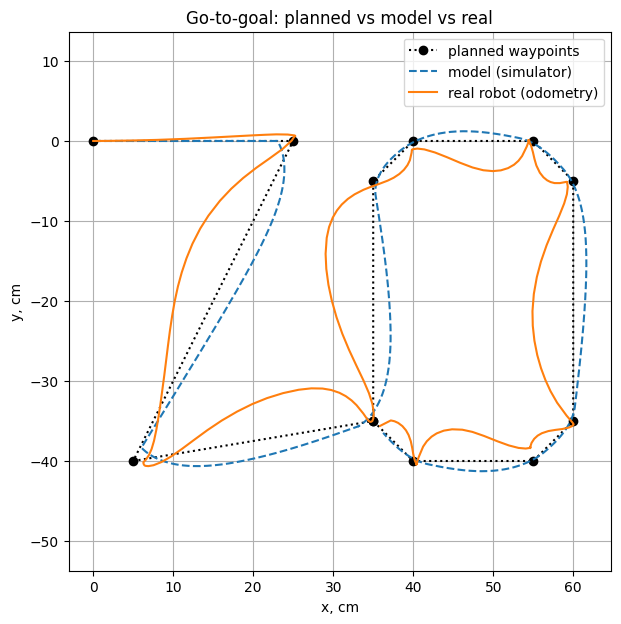

In [7]:
# 1. Planned path vs simulated vs real
plt.figure(figsize=(7, 7))
plt.plot(wp[:, 0], wp[:, 1], 'k:o', label='planned waypoints')
if HAVE_SIM:
    plt.plot(x_s, y_s, '--', label='model (simulator)')
plt.plot(x_r, y_r, label='real robot (odometry)')
plt.axis('equal'); plt.grid(True); plt.legend()
plt.xlabel('x, cm'); plt.ylabel('y, cm')
plt.title('Go-to-goal: planned vs model vs real')
plt.show()

In [8]:
# 2. How close did each run get to each waypoint?
def waypoint_miss(x, y, wp):
    return np.array([np.min(np.hypot(x - px, y - py)) for px, py in wp])

miss_r = waypoint_miss(x_r, y_r, wp)
miss_s = waypoint_miss(x_s, y_s, wp) if HAVE_SIM else None
for i in range(len(wp)):
    sim_txt = f'sim {miss_s[i]:5.2f} cm | ' if HAVE_SIM else ''
    print(f'Waypoint {i:2d} {tuple(int(v) for v in wp[i])}: {sim_txt}real {miss_r[i]:5.2f} cm')

# 3. Run time
sim_t = f'sim {(t_s[-1]-t_s[0])/1000:.1f} s | ' if HAVE_SIM else ''
print(f'Run time: {sim_t}real {(t_r[-1]-t_r[0])/1000:.1f} s')

Waypoint  0 (0, 0): sim  0.00 cm | real  0.00 cm
Waypoint  1 (25, 0): sim  1.75 cm | real  0.19 cm
Waypoint  2 (5, -40): sim  1.91 cm | real  1.29 cm
Waypoint  3 (35, -35): sim  0.68 cm | real  0.10 cm
Waypoint  4 (35, -5): sim  0.45 cm | real  0.80 cm
Waypoint  5 (40, 0): sim  0.15 cm | real  1.03 cm
Waypoint  6 (55, 0): sim  0.27 cm | real  0.48 cm
Waypoint  7 (60, -5): sim  0.20 cm | real  0.77 cm
Waypoint  8 (60, -35): sim  0.30 cm | real  0.22 cm
Waypoint  9 (55, -40): sim  0.16 cm | real  1.65 cm
Waypoint 10 (40, -40): sim  0.27 cm | real  0.21 cm
Waypoint 11 (35, -35): sim  0.68 cm | real  0.10 cm
Run time: sim 26.7 s | real 15.3 s


## Measured end point
Tape measurement of the real robot's final position (same origin and axes as the odometry):

- Measured: x = **___ cm**, y = **___ cm**
- Last waypoint: (35, -35)
- Last line of odometry_data_real.txt: (35.86, -35.61)
- Measured vs last waypoint: ___ cm; measured vs odometry: ___ cm

## Answers (3-6 sentences)
*Fill in after the sim run and the tape measurement.*

In [9]:
# 4. Largest deviation from the straight line of each leg
def arrival_indices(x, y, wp, eps=EPS):
    idx = [0]
    for k in range(1, len(wp)):
        i = idx[-1] + 1
        while i < len(x) - 1 and np.hypot(x[i]-wp[k,0], y[i]-wp[k,1]) >= eps:
            i += 1
        idx.append(i)
    return idx

def leg_cross_track(x, y, wp):
    idx = arrival_indices(x, y, wp); out = []
    for k in range(len(wp) - 1):
        a, d = wp[k].astype(float), (wp[k+1] - wp[k]).astype(float)
        L = np.hypot(*d)
        seg = np.column_stack([x[idx[k]:idx[k+1]+1], y[idx[k]:idx[k+1]+1]]) - a
        out.append(np.max(np.abs((seg[:,0]*d[1] - seg[:,1]*d[0]) / L)))
    return np.array(out)

ct_r = leg_cross_track(x_r, y_r, wp)
ct_s = leg_cross_track(x_s, y_s, wp) if HAVE_SIM else None
for k in range(len(ct_r)):
    sim_txt = f'sim {ct_s[k]:4.1f} cm | ' if HAVE_SIM else ''
    print(f'Leg {k+1:2d}: max off-line  {sim_txt}real {ct_r[k]:4.1f} cm')

Leg  1: max off-line  sim  0.0 cm | real  0.8 cm
Leg  2: max off-line  sim  2.3 cm | real  5.5 cm
Leg  3: max off-line  sim  2.3 cm | real  5.4 cm
Leg  4: max off-line  sim  2.2 cm | real  5.9 cm
Leg  5: max off-line  sim  1.6 cm | real  1.7 cm
Leg  6: max off-line  sim  1.2 cm | real  3.8 cm
Leg  7: max off-line  sim  1.1 cm | real  2.3 cm
Leg  8: max off-line  sim  1.6 cm | real  5.1 cm
Leg  9: max off-line  sim  1.2 cm | real  1.9 cm
Leg 10: max off-line  sim  1.3 cm | real  4.0 cm
Leg 11: max off-line  sim  1.1 cm | real  2.1 cm


In [10]:
print('Last odometry line (real): x = %.2f, y = %.2f' % (x_r[-1], y_r[-1]))
print('Distance to last waypoint: %.2f cm' % np.hypot(x_r[-1]-wp[-1,0], y_r[-1]-wp[-1,1]))

Last odometry line (real): x = 35.86, y = -35.61
Distance to last waypoint: 1.06 cm


## Answers

The robot hit all 12 waypoints within 1.7 cm and finished 1.06 cm from the last goal, but it didn't stay on the straight lines. On the long legs it drifted about 5-6 cm off the line, while the simulator stayed within about 2 cm. Nothing was overshot, the corners were just rounded, and I think the cause is TURN_IN_PLACE = 1.0 with K_TH = 3.0: the robot starts driving before it has finished turning, so it follows an arc. Since the program and gains are identical in both runs, the extra error on the real robot probably comes from the motors and the slow loop. I didn't measure the final position by hand, so I can't say for sure how much is localization, but from the logs it looks mostly like a control problem.
